In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy

today = date.today()

In [ ]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data))
    return fig

**Observed ratios for each winning state in each mapped region**

In [3]:
filename = '/home/ctrader/region_similarity/data/regions_25kb_CT20230103.epilogos.maxstateperbin.officialstateorder.allmapped.bed'
f = open(filename, 'r')
winning_state_data = []
for line in f.readlines():
    winning_state_data.append(np.float_(line.strip().split('|')[1].split(';')))
winning_state_data = np.array(winning_state_data)
f.close()

In [4]:
num_states = 18
counts = []
for region in range(len(winning_state_data)):
    region_states = (winning_state_data[region][~np.isnan(winning_state_data[region])]).astype(int)
    state_count = np.bincount(region_states)
    state_count = np.append(state_count, np.int_([0] * (num_states - len(state_count))))
    counts.append(state_count)
counts = np.array(counts)

In [5]:
observed = (counts.T / np.sum(counts, axis=1)).T

/tmp/ipykernel_67539/407407469.py:1: RuntimeWarning: invalid value encountered in true_divide
  observed = (counts.T / np.sum(counts, axis=1)).T


In [6]:
filename = '/home/ctrader/region_similarity/data/rank_based/epilogos.winningstateperbin.genomewide.counts.expectedratio.officialorder.CT20230103.tsv'
f = open(filename, 'r')
expected = np.float_(f.readlines()[2].strip().split('\t'))
f.close()

In [7]:
ooe = observed / expected

In [59]:
t = np.nanmean(ooe, axis=1)

DescribeResult(nobs=98629, minmax=(nan, nan), mean=nan, variance=nan, skewness=nan, kurtosis=nan)
ModeResult(mode=array([0.1009542]), count=array([13580]))


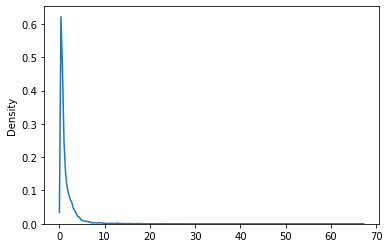

In [60]:
t0 = kde_wrapper(t)

In [11]:
def sigmoid_func(val_arr, scaling_factor=5, method='array'):
    # max rank
    if method == 'array':
        max_val = np.max(val_arr, axis=0)
    elif method == 'full':
        max_val = np.max(val_arr)

    # scaling between [-scaling_factor, scaling_factor]
    x = (val_arr / (max_val / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

In [50]:
def rank_regions(arr):
    # rank each region
    ranked_regions = rankdata(arr, axis=0)

    # find the number of regions with 0 values for each factor
    factor_num_zero = len(arr) - np.count_nonzero(arr, axis=0)

    # adjusting/resetting ranks
    ranked_regions = ranked_regions - factor_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)

    return ranked_regions

In [57]:
# top 1000 regions and values
def find_top_regions(sim_m):
    top_regions_all = []
    top_vals_all = []
    for i in range(len(sim_m)):
        top_regions = np.argsort(-sim_m[i])[:1001]
        top_regions = top_regions[top_regions != i][:1000]
        top_regions_all.append(top_regions)
        top_vals_all.append(sim_m[i, top_regions])
    top_regions_all = np.array(top_regions_all)
    top_vals_all = np.array(top_vals_all)
    return top_regions_all, top_vals_all

In [51]:
ranked_regions = rank_regions(ooe)

In [53]:
sig = sigmoid_func(ranked_regions, method='array')

In [56]:
conv = np.matmul(sig, sig.T) / len(sig[0])

In [58]:
top_regions, top_vals = find_top_regions(conv)
del conv

In [61]:
filename = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230103.priors.maxstate.epilogos.tsv'
epi_priors = np.genfromtxt(filename, delimiter='\t', dtype=float)

DescribeResult(nobs=98629, minmax=(0.0, 0.9933071490757153), mean=0.0078081011269155835, variance=0.00022339968917078264, skewness=39.77263809946892, kurtosis=2052.7371804091013)
ModeResult(mode=array([0.00679354]), count=array([13580]))


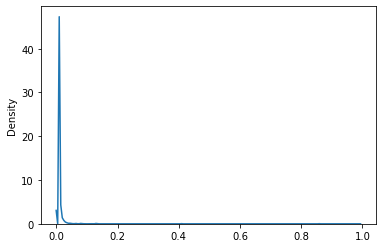

In [62]:
fig = kde_wrapper(epi_priors)

In [23]:
filename = '/home/ctrader/region_similarity/data/regions_25kb_CT20230103.epilogos.maxstateperbin.officialstateorder.allmapped.bed'
f = open(filename, 'r')
x = f.readlines()
f.close()

In [63]:
top_p = -np.sort(-epi_priors)[:10]
top_r = np.argsort(-epi_priors)[:10]
for r, p in zip(top_r, top_p):
    g = x[r].split('|')[0].split('\t')
    print(g[0] + ':' + g[1] + '-' + g[2], '    prior = ' + str(np.round(p, 4)))

chr3:134353200-134378200     prior = 0.9933
chr7:50345400-50370400     prior = 0.992
chr22:36319600-36344600     prior = 0.9895
chr4:10093000-10118000     prior = 0.9885
chr22:37217600-37242600     prior = 0.9848
chr1:169687400-169712400     prior = 0.8992
chr19:38700400-38725400     prior = 0.8816
chr17:50187400-50212400     prior = 0.8589
chr5:170260000-170285000     prior = 0.8493
chr19:1250200-1275200     prior = 0.8041


Percentile epi priors

In [72]:
ooe_mean = np.nanmean(ooe, axis=1)

/tmp/ipykernel_67539/2155104413.py:1: RuntimeWarning: Mean of empty slice
  ooe_mean = np.nanmean(ooe, axis=1)


In [73]:
ooe_mean.shape

(98629,)

In [98]:
ooe_mean_corr = np.where(np.isnan(ooe_mean), 0, ooe_mean)

In [99]:
ooe_mean_per = []
for i in range(len(ooe_mean_corr)):
    ooe_mean_per.append(stats.percentileofscore(ooe_mean_corr, ooe_mean[i]))
ooe_mean_per = np.array(ooe_mean_per)
ooe_mean_per = np.where(np.isnan(ooe_mean_per), 0, ooe_mean_per)

DescribeResult(nobs=98629, minmax=(0.0, 1.0), mean=0.49466216020507625, variance=0.08806282616812976, skewness=-0.07109393059150762, kurtosis=-1.1330154573949547)
ModeResult(mode=array([0.17221608]), count=array([13580]))


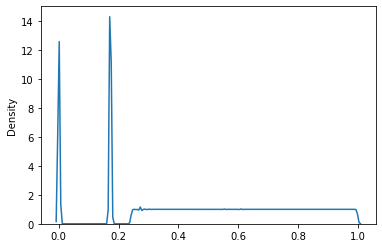

In [104]:
fig = kde_wrapper(ooe_mean_per / 100)

rank priors

In [124]:
ooe_mean_rank = rankdata(ooe_mean_corr, axis=0, method='average')

In [125]:
print(np.max(ooe_mean_rank))
print(np.min(ooe_mean_rank))

98629.0
5098.0


DescribeResult(nobs=98629, minmax=(0.051688651410842654, 1.0), mean=0.5000050695028846, variance=0.08302452607115822, skewness=0.014118240520502449, kurtosis=-1.223109152001324)
ModeResult(mode=array([0.17221608]), count=array([13580]))


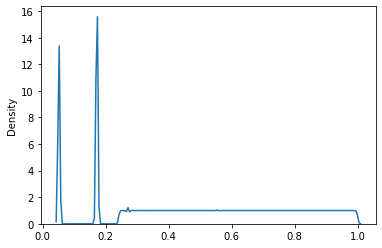

In [126]:
fig = kde_wrapper(ooe_mean_rank / np.max(ooe_mean_rank))

DHS and TF Priors

In [64]:
filename = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221215.priors.DHS.TF.epilogos.tsv'
old_priors = np.genfromtxt(filename, delimiter='\t', dtype=float)

In [66]:
DHS_priors = old_priors[:, 0]
TF_priors = old_priors[:, 1]

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.7750675736719176, variance=0.03749311145409955, skewness=-0.2765826153794733, kurtosis=-1.515108933379171)
ModeResult(mode=array([0.5]), count=array([19746]))


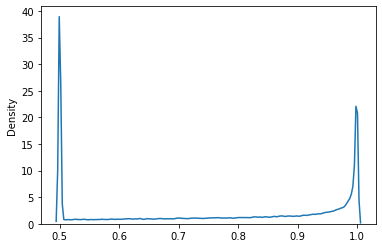

In [67]:
fig = kde_wrapper(DHS_priors)

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.9675065984061062, variance=0.014947010418593417, skewness=-3.5618209614514487, kurtosis=10.688768844346093)
ModeResult(mode=array([1.]), count=array([12564]))


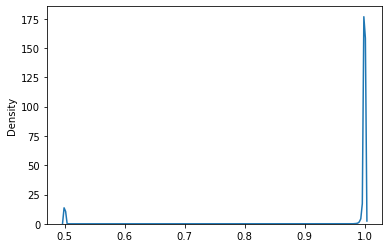

In [68]:
fig = kde_wrapper(TF_priors)